# PBL 2: Alternate EM (Gaussian Mixture Model) on the Pima Diabetes Data

**Project:** Explainable Machine Learning for Early Prediction of Diabetes Risk Using Clinical Data
**Team 3:** Jai (RA2411026010131), Aggam (RA2411026010139), Alphin (RA2411026010177)
**Assigned Unit 3 topic:** Alternate EM (Expectation-Maximisation)

In PBL 1 we predicted diabetes **with** the label. Here we ask a different question: **without using the label**, do patients fall into natural groups (risk profiles)? We answer it with the EM algorithm, which fits a Gaussian Mixture Model by **alternating** two steps (E-step and M-step) until it converges.

| # | Rubric item | Marks | Section |
|---|---|---|---|
| 1 | Dataset preparation and feature selection relevant to Unit 3 | 2 | A, B |
| 2 | Correct implementation of the Unit 3 algorithm (EM / GMM) | 4 | C |
| 3 | Algorithm evaluation, visualisation and result interpretation | 2 | D, E |
| 4 | Demonstration, conceptual understanding and viva | 2 | whole notebook |

## Setup
Import libraries, set one random seed, and create the figure folder.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.exceptions import ConvergenceWarning

RANDOM_STATE = 42  # used everywhere so results are reproducible
os.makedirs("figures/pbl2", exist_ok=True)

# Section A: The Idea

## A.1 Why clustering for diabetes?
A label like "diabetic / not diabetic" hides a lot. Two diabetic patients can look very different: one young with very high glucose, another older with high BMI and only mildly raised glucose. **Clustering** finds such groups from the measurements alone. If the groups have very different diabetes rates, they are useful **risk profiles**, and they are easy to explain ("this patient belongs to the high-glucose, high-BMI group").

## A.2 Gaussian Mixture Model (GMM)
A GMM assumes each patient $x$ was produced by one of $K$ hidden groups, and each group is a Gaussian (bell curve) in feature space:

$$p(x) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k)$$

- $\pi_k$ = mixing weight (share of patients in group $k$, the weights sum to 1)
- $\mu_k$ = mean vector of group $k$ (the "typical" patient of that group)
- $\Sigma_k$ = covariance matrix of group $k$ (its spread and shape)

The group of each patient is **hidden** (a latent variable $z$). If we knew $z$ we could fit each Gaussian directly; if we knew the Gaussians we could guess $z$. EM breaks this chicken-and-egg problem by **alternating** between the two.

## A.3 The (alternate) EM algorithm
Start with a guess of $\pi, \mu, \Sigma$, then repeat:

**E-step** (guess the hidden groups): compute the **responsibility** of group $k$ for patient $i$, i.e. the probability that $i$ belongs to $k$:

$$\gamma_{ik} = \frac{\pi_k \, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)}{\sum_{j=1}^{K} \pi_j \, \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}$$

**M-step** (refit the Gaussians, using the responsibilities as soft weights), with $N_k = \sum_i \gamma_{ik}$:

$$\pi_k = \frac{N_k}{N} \qquad \mu_k = \frac{1}{N_k}\sum_{i} \gamma_{ik}\, x_i \qquad \Sigma_k = \frac{1}{N_k}\sum_i \gamma_{ik}\,(x_i-\mu_k)(x_i-\mu_k)^\top$$

Each round can only **increase** (never decrease) the log-likelihood

$$\log L = \sum_{i=1}^{N} \log \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$$

so EM stops when the increase is below a small tolerance. It finds a **local** maximum, so we restart it from several random starts (`n_init`) and keep the best.

**Hard vs soft EM.** If the E-step gives each patient to **one** group only ($\gamma_{ik} \in \{0, 1\}$) and all groups share the same round covariance, EM becomes **K-means**: assign each point to the nearest centre, then move each centre to the mean of its points. So K-means is the "hard" version of the same alternating idea. We compare both in Section D.

# Section B: Dataset Preparation and Feature Selection *(Rubric 1)*

## B.1 Load the data
We reuse the Pima data saved in PBL 1 (`data/pima.csv`, 768 women, 8 measurements, label `Outcome`).
As in PBL 1, a `0` in Glucose, BloodPressure, SkinThickness, Insulin or BMI is impossible, so it means **missing**.

In [2]:
pima = pd.read_csv("data/pima.csv")
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
pima[zero_cols] = pima[zero_cols].replace(0, np.nan)

print(pima.shape)
missing_percent = (pima.isnull().mean() * 100).round(1)
missing_percent

(768, 9)


Pregnancies                  0.0
Glucose                      0.7
BloodPressure                4.6
SkinThickness               29.6
Insulin                     48.7
BMI                          1.4
DiabetesPedigreeFunction     0.0
Age                          0.0
Outcome                      0.0
dtype: float64

**Observation:** The data has 768 patients. Two columns are mostly missing: **Insulin (48.7%)** and **SkinThickness (29.6%)**. BloodPressure (4.6%), BMI (1.4%) and Glucose (0.7%) have only a few missing values, and Pregnancies, DiabetesPedigreeFunction and Age have none.

## B.2 Feature selection for EM
EM fits Gaussians, so the choice of features matters more than for a tree model:

1. **Drop the label.** Clustering is unsupervised: `Outcome` is kept aside **only to evaluate** the clusters afterwards. Using it would be cheating.
2. **Drop heavily-missing features** (more than 25% missing). If we fill half of the Insulin column with one median value, hundreds of patients get the *same* value, and the GMM happily spends a whole Gaussian on that fake spike. So Insulin and SkinThickness are removed. The other three have only a few missing values, which we fill with the median.
3. **Drop discrete counts.** `Pregnancies` takes only whole numbers (0, 1, 2, ...), and many patients share exactly the same value. A Gaussian can shrink onto one repeated value (for example "0 pregnancies") and get an almost infinite density there, which fakes a better fit. It is also partly covered by `Age`. So it is removed too.
4. **Reduce skew.** A Gaussian is symmetric, so strongly right-skewed features fit badly. We apply $x' = \log(1 + x)$ to any feature with skewness above 1.
5. **Standardise.** The Gaussians use distances, so a feature measured in large numbers (Glucose, about 120) would outweigh one in small numbers (DiabetesPedigreeFunction, about 0.5). We use $z = (x - \mu)/\sigma$.

The cell below applies rules 1 to 3 in code (for rule 2 the 25% threshold, not a hand-written list, decides).

In [3]:
label = pima["Outcome"]                       # kept aside for evaluation only
candidates = pima.drop(columns="Outcome")

keep = missing_percent[missing_percent <= 25].index.drop("Outcome")
print("Dropped (too much missing):", [c for c in candidates.columns if c not in keep])
features = [c for c in keep if c != "Pregnancies"]   # rule 3: drop the discrete count
print("Kept:", features)

# fill the few missing values with the median of each column
imputer = SimpleImputer(strategy="median")
X_raw = pd.DataFrame(imputer.fit_transform(pima[features]), columns=features)
X_raw.skew().round(2)

Dropped (too much missing): ['SkinThickness', 'Insulin']
Kept: ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction', 'Age']


Glucose                     0.54
BloodPressure               0.14
BMI                         0.60
DiabetesPedigreeFunction    1.92
Age                         1.13
dtype: float64

**Observation:** The 25% rule removes **SkinThickness and Insulin**, and rule 3 removes Pregnancies, leaving **5 features**: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction and Age. Two of them are strongly right-skewed: **DiabetesPedigreeFunction (1.92)** and **Age (1.13)**. The other three have skewness between 0.14 and 0.60, which is close enough to symmetric for a Gaussian.

## B.3 Log transform and standardise
$$x' = \log(1 + x) \qquad z = \frac{x' - \mu}{\sigma}$$
We log only the features with skewness above 1, then standardise every feature. We also check the correlations: two almost identical features would count the same information twice.

Log-transformed: ['DiabetesPedigreeFunction', 'Age']
Skewness after: {'Glucose': 0.54, 'BloodPressure': 0.14, 'BMI': 0.6, 'DiabetesPedigreeFunction': 1.12, 'Age': 0.61}


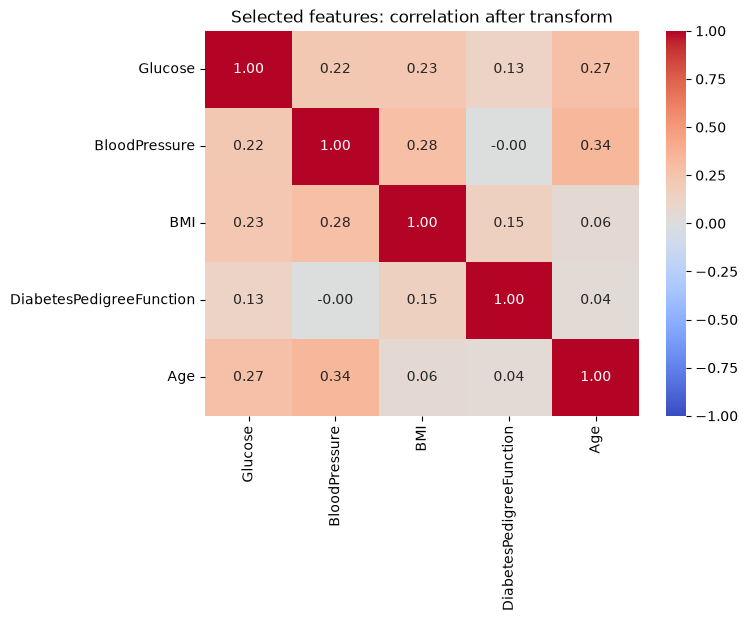

In [4]:
skewed = list(X_raw.columns[X_raw.skew() > 1])
print("Log-transformed:", skewed)

X_log = X_raw.copy()
X_log[skewed] = np.log1p(X_log[skewed])     # log(1 + x)
print("Skewness after:", X_log.skew().round(2).to_dict())

scaler = StandardScaler()
X = scaler.fit_transform(X_log)              # numpy array, mean 0 and sd 1 per column

plt.figure(figsize=(7, 5))
sns.heatmap(pd.DataFrame(X, columns=features).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Selected features: correlation after transform")
plt.savefig("figures/pbl2/fig01_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The log transform lowers the skewness of DiabetesPedigreeFunction from 1.92 to 1.12 and of Age from 1.13 to 0.61. All correlations between the selected features are weak: the largest is **BloodPressure-Age (0.34)**. So no feature is a near-duplicate of another, and each one adds its own information to the clusters.

# Section C: Implementing EM *(Rubric 2)*

## C.1 How many groups? (choosing $K$ with BIC)
More groups always fit the data better, so the likelihood alone would pick a huge $K$. The **Bayesian Information Criterion** adds a penalty for the number of parameters $p$:

$$\text{BIC} = -2 \log L + p \log N \qquad \text{AIC} = -2\log L + 2p$$

Lower is better. We try $K = 1 \dots 8$ and two covariance shapes:
- `full`: each group has its own tilted ellipse (features can be correlated inside a group)
- `diag`: each group's ellipse is aligned with the axes (features independent inside a group, fewer parameters)

Every model uses `n_init=10` (10 random starts, best one kept) because EM only finds a local maximum.

In [5]:
rows = []
for cov in ["full", "diag"]:
    for k in range(1, 9):
        gmm = GaussianMixture(n_components=k, covariance_type=cov,
                              n_init=10, random_state=RANDOM_STATE).fit(X)
        rows.append([cov, k, gmm.bic(X), gmm.aic(X)])
bic_table = pd.DataFrame(rows, columns=["covariance", "K", "BIC", "AIC"])

best = bic_table.loc[bic_table["BIC"].idxmin()]
best_k, best_cov = int(best["K"]), best["covariance"]
print("Lowest BIC:", best_cov, "covariance with K =", best_k)
bic_table.pivot(index="K", columns="covariance", values="BIC").round(1)

Lowest BIC: diag covariance with K = 3


covariance,diag,full
K,,
1,10963.9,10737.2
2,10524.0,10509.0
3,10422.4,10493.4
4,10423.5,10575.9
5,10435.0,10622.7
6,10443.4,10704.6
7,10469.3,10756.7
8,10534.7,10892.0


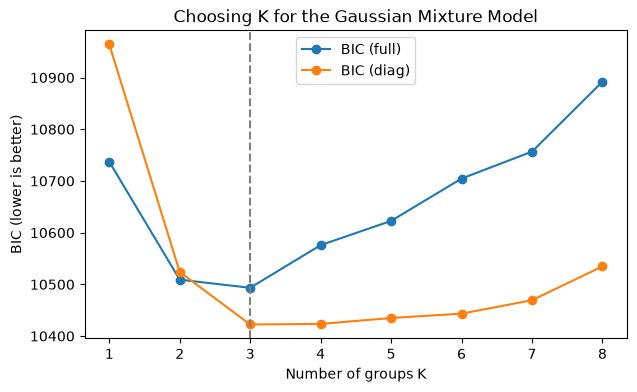

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for cov in ["full", "diag"]:
    part = bic_table[bic_table["covariance"] == cov]
    ax.plot(part["K"], part["BIC"], marker="o", label=f"BIC ({cov})")
ax.axvline(best_k, color="grey", linestyle="--")
ax.set_xlabel("Number of groups K")
ax.set_ylabel("BIC (lower is better)")
ax.set_title("Choosing K for the Gaussian Mixture Model")
ax.legend()
plt.savefig("figures/pbl2/fig02_bic.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The lowest BIC is **`diag` covariance with K = 3** (10422.4). K = 4 is almost tied (10423.5), so the data does not strongly prefer one over the other; BIC picks the simpler model. With `full` covariance, BIC is only better at K = 2 and grows quickly after that, because each extra group adds a whole covariance matrix of parameters. We continue with **3 groups, diagonal covariance**.

## C.2 Watching EM alternate, step by step
`GaussianMixture` normally hides its loop. With `max_iter=1` and `warm_start=True`, each call to `.fit()` runs **exactly one E-step and one M-step**, starting from where the last call stopped. So we can record the average log-likelihood per patient after every round and see it climb.
(scikit-learn warns that one iteration "did not converge"; that is expected here, so we silence it.)

In [7]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

em_steps = GaussianMixture(n_components=best_k, covariance_type=best_cov,
                           max_iter=1, warm_start=True, init_params="random",  # random start

                           random_state=RANDOM_STATE)
log_lik, snapshots = [], {}
for step in range(1, 61):
    em_steps.fit(X)                          # one E-step + one M-step
    log_lik.append(em_steps.lower_bound_)    # average log-likelihood per patient
    if step in [1, 3, 60]:
        snapshots[step] = em_steps.predict(X)

print("Log-likelihood after step 1, 5, 20, 60:",
      [round(log_lik[i - 1], 4) for i in [1, 5, 20, 60]])
print("Never decreased:", bool(np.all(np.diff(log_lik) >= -1e-9)))

Log-likelihood after step 1, 5, 20, 60: [np.float64(-7.0939), np.float64(-7.0393), np.float64(-6.6669), np.float64(-6.6457)]
Never decreased: True


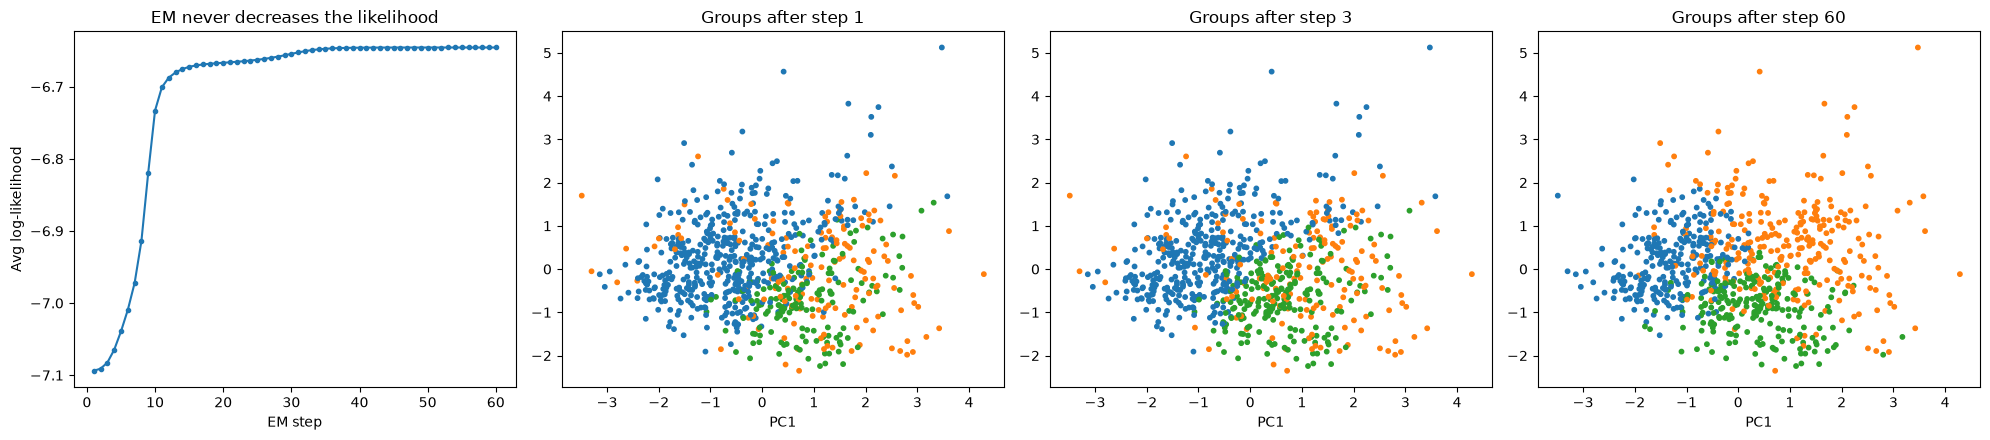

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)                   # 2-D view of the data, for plotting only

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].plot(range(1, 61), log_lik, marker=".")
axes[0].set_xlabel("EM step")
axes[0].set_ylabel("Avg log-likelihood")
axes[0].set_title("EM never decreases the likelihood")
for ax, step in zip(axes[1:], [1, 3, 60]):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=snapshots[step], cmap="tab10", s=10, vmax=9)
    ax.set_title(f"Groups after step {step}")
    ax.set_xlabel("PC1")
plt.tight_layout()
plt.savefig("figures/pbl2/fig03_em_steps.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The average log-likelihood climbs from **-7.094 after step 1 to -6.646 after step 60**, and it **never decreases**, exactly as EM theory says. Most of the gain comes in about the first 12 steps, then there is a flat stretch and a second rise before the curve settles. The scatter plots show the alternation at work: after step 1 the groups are mixed, and by step 60 there are three clearly separated regions.

## C.3 Final model
Now the normal fit: run EM to convergence (`tol=1e-3`, up to 500 steps) from 10 random starts and keep the best.

In [9]:
gmm = GaussianMixture(n_components=best_k, covariance_type=best_cov, n_init=10,
                      max_iter=500, random_state=RANDOM_STATE).fit(X)

print("Converged:", gmm.converged_, "after", gmm.n_iter_, "steps")
print("Average log-likelihood per patient:", round(gmm.score(X), 4))

clusters = gmm.predict(X)              # hard label = group with highest responsibility
resp = gmm.predict_proba(X)            # soft labels: the responsibilities gamma_ik
print("Mixing weights pi_k:", gmm.weights_.round(3))

Converged: True after 25 steps
Average log-likelihood per patient: -6.647
Mixing weights pi_k: [0.374 0.296 0.33 ]


## C.4 Checking the library against the formulas
To show we understand what `GaussianMixture` does, we recompute one **E-step** and one **M-step** by hand with the formulas from A.3, using the fitted parameters, and compare.
- E-step: $\gamma_{ik} \propto \pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$, normalised per patient.
- M-step: $\pi_k = N_k / N$, $\mu_k = \sum_i \gamma_{ik} x_i / N_k$. At convergence, one more M-step should give back (almost) the same parameters.

In [10]:
# covariance of each group as a full matrix (a 'diag' model stores only the diagonal)
if best_cov == "full":
    covs = gmm.covariances_
else:
    covs = [np.diag(c) for c in gmm.covariances_]

# E-step by hand
weighted = np.column_stack([gmm.weights_[k] * multivariate_normal(gmm.means_[k], covs[k]).pdf(X)
                            for k in range(best_k)])
resp_hand = weighted / weighted.sum(axis=1, keepdims=True)
print("E-step: max difference from predict_proba =", np.abs(resp_hand - resp).max())

# M-step by hand
N_k = resp_hand.sum(axis=0)
pi_hand = N_k / len(X)
mu_hand = (resp_hand.T @ X) / N_k[:, None]
print("M-step: max difference in weights =", np.abs(pi_hand - gmm.weights_).max())
print("M-step: max difference in means   =", np.abs(mu_hand - gmm.means_).max())

E-step: max difference from predict_proba = 1.3322676295501878e-15
M-step: max difference in weights = 0.0034321709258954836
M-step: max difference in means   = 0.007327811689738728


**Observation:** The hand-written E-step matches `predict_proba` to **1.3e-15**, which is just rounding error, so the library computes exactly the responsibility formula from A.3. One more hand-written M-step changes the weights by at most 0.0034 and the means by at most 0.0073 (in standard deviations). The change is small but not zero because EM stops once the gain is below the tolerance, not at the exact maximum. In other words, the fitted parameters are (almost) a fixed point of the E and M steps, which is what convergence means.

## C.5 Hard EM: K-means with the same $K$
K-means alternates the same two steps but with hard assignments:
$$\text{assign: } z_i = \arg\min_k \lVert x_i - \mu_k \rVert^2 \qquad \text{update: } \mu_k = \text{mean of the points with } z_i = k$$

In [11]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X)
km_clusters = kmeans.labels_
print("Agreement between GMM and K-means (ARI):",
      round(adjusted_rand_score(clusters, km_clusters), 3))

Agreement between GMM and K-means (ARI): 0.385


# Section D: Evaluation and Visualisation *(Rubric 3)*

## D.1 Metrics
There is no "accuracy" for clustering, so we use:
- **Silhouette score** (internal: are groups compact and well separated?), from −1 to 1, higher is better:
$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)}$$
  $a_i$ = mean distance from $i$ to its own group, $b_i$ = mean distance to the nearest other group.
- **Adjusted Rand Index (ARI)** (external: do the groups line up with the real `Outcome`?). 1 = identical grouping, 0 = no better than random.
- **Log-likelihood / BIC** (how well the model explains the data; only defined for the GMM).

In [12]:
results = pd.DataFrame({
    "Silhouette": [silhouette_score(X, clusters), silhouette_score(X, km_clusters)],
    "ARI vs Outcome": [adjusted_rand_score(label, clusters), adjusted_rand_score(label, km_clusters)],
}, index=["GMM (soft EM)", "K-means (hard EM)"])
results.round(3)

,Silhouette,ARI vs Outcome
GMM (soft EM),0.143,0.101
K-means (hard EM),0.216,0.185


**Observation:** K-means scores higher on both metrics: silhouette **0.216 vs 0.143** and ARI with Outcome **0.185 vs 0.101**. The silhouette uses plain distances, which favours K-means's round, equal-sized clusters; the GMM groups may be stretched along some features and have different spreads. Both ARI values are low. This is expected: diabetes is not a separate island in the data but a gradual risk, so the groups are **risk profiles, not diagnoses**. GMM and K-means agree only moderately with each other (ARI 0.385).

## D.2 What does each group look like? (cluster profiles)
For interpretation we go back to the **original units** (before log and scaling) and show the median of each feature per group, together with the group size and its **diabetes rate** (share of `Outcome = 1`, which the model never saw).

In [13]:
profile = X_raw.copy()
profile["cluster"] = clusters
profile["Outcome"] = label.values

summary = profile.groupby("cluster")[features].median().round(1)
summary["patients"] = profile.groupby("cluster").size()
summary["diabetes_rate_%"] = (profile.groupby("cluster")["Outcome"].mean() * 100).round(1)
summary = summary.sort_values("diabetes_rate_%")
summary

,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age,patients,diabetes_rate_%
cluster,,,,,,,
2,102.0,65.0,29.7,0.3,23.0,269,10.8
1,125.0,75.0,32.4,0.3,38.0,237,38.0
0,130.0,76.0,34.6,0.7,35.0,262,56.9


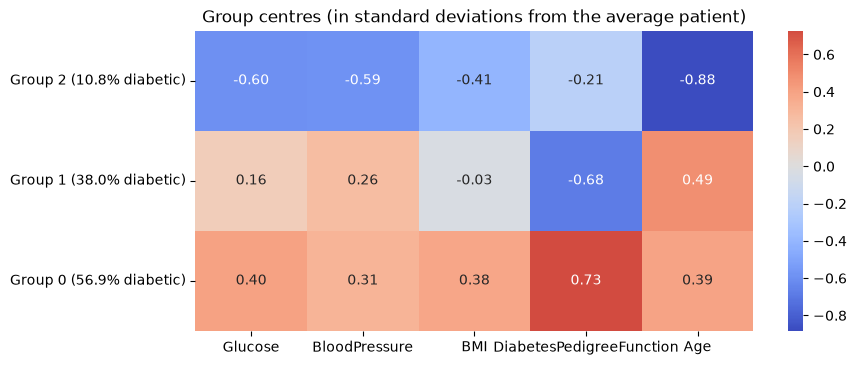

In [14]:
# heatmap of the standardised group means: red = above average, blue = below
means = pd.DataFrame(gmm.means_, columns=features).loc[summary.index]
means.index = [f"Group {c} ({r}% diabetic)" for c, r in zip(summary.index, summary["diabetes_rate_%"])]

plt.figure(figsize=(9, 0.8 * best_k + 1.5))
sns.heatmap(means, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Group centres (in standard deviations from the average patient)")
plt.savefig("figures/pbl2/fig04_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** The three groups have very different diabetes rates, even though the label was never used:
- **Group 2, low risk (269 patients, 10.8% diabetic):** the youngest (median age 23), with the lowest glucose (102), blood pressure and BMI.
- **Group 1, older (237 patients, 38.0% diabetic):** median age 38, glucose 125, and the lowest family history (DiabetesPedigreeFunction 0.68 SD below average).
- **Group 0, high risk (262 patients, 56.9% diabetic):** the highest glucose (130), BMI (34.6) and family history (0.73 SD above average).

The risk is **five times higher** in Group 0 than in Group 2. This matches clinical knowledge: high glucose combined with obesity and family history is the classic Type 2 risk profile.

## D.3 The groups in 2-D
PCA projects the selected features onto the 2 directions with the most variance, only to draw them. Left: GMM groups. Middle: K-means groups. Right: the real label, which the clustering never saw.

Variance explained by PC1 + PC2: 56.1 %


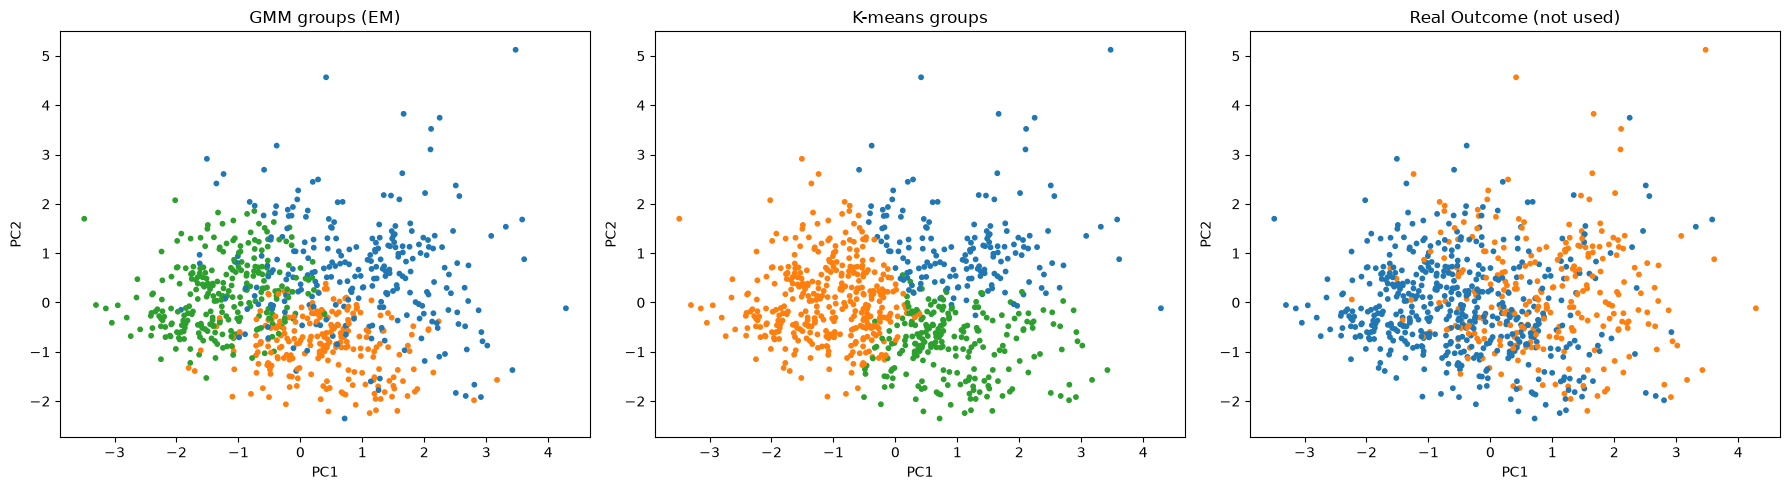

In [15]:
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, colours, title in zip(axes, [clusters, km_clusters, label],
                              ["GMM groups (EM)", "K-means groups", "Real Outcome (not used)"]):
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=colours, cmap="tab10", s=10, vmax=9)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.savefig("figures/pbl2/fig05_clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** PC1 and PC2 keep 56.1% of the variance, so this 2-D view is only a rough picture. In the GMM plot (green = Group 2, orange = Group 1, blue = Group 0), the low-risk group sits on the left, and the two higher-risk groups split the right side into an upper and a lower part. In the real-Outcome plot (orange = diabetic), diabetic patients are also more common on the right, but both colours overlap everywhere. This explains the low ARI: the clusters follow the risk gradient, but no clean border separates diabetic from non-diabetic patients.

## D.4 Soft assignments: how sure is the model?
A big advantage of EM over K-means is that each patient gets a **probability** for every group. A patient whose highest responsibility is close to 1 clearly belongs to one profile; one near $1/K$ sits on a border, and a clinician should look at them more carefully.

Patients with max responsibility < 0.8: 235 (30.6%)


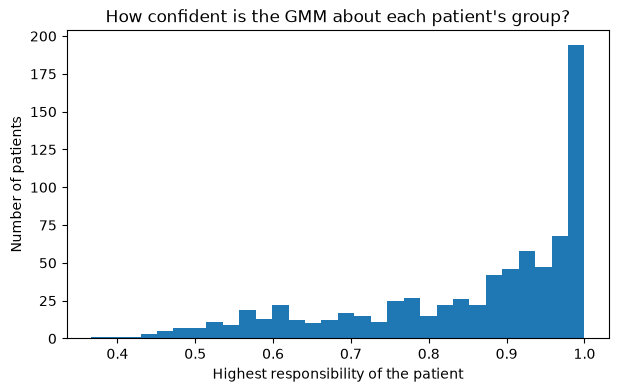

In [16]:
max_resp = resp.max(axis=1)
print("Patients with max responsibility < 0.8:", (max_resp < 0.8).sum(),
      f"({(max_resp < 0.8).mean() * 100:.1f}%)")

plt.figure(figsize=(7, 4))
plt.hist(max_resp, bins=30, color="tab:blue")
plt.xlabel("Highest responsibility of the patient")
plt.ylabel("Number of patients")
plt.title("How confident is the GMM about each patient's group?")
plt.savefig("figures/pbl2/fig06_responsibility.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** **235 patients (30.6%)** have no group with a responsibility of 0.8 or more. They sit between profiles. K-means would still force them into one group without any warning; the GMM tells us which patients are uncertain cases, which is useful for explanation ("this patient is 55% high-risk profile, 45% older profile").

## D.5 Stability: does EM find the same groups from different starts?
EM only reaches a local maximum. We refit with **one** random start (`n_init=1`) for 10 different seeds and compare each result with our final model using ARI (1 = same grouping).

In [17]:
stability = []
for seed in range(10):
    g = GaussianMixture(n_components=best_k, covariance_type=best_cov, n_init=1,
                        random_state=seed).fit(X)
    stability.append([seed, g.score(X), adjusted_rand_score(clusters, g.predict(X))])
stability = pd.DataFrame(stability, columns=["seed", "avg_log_lik", "ARI_vs_final"])
print("ARI mean:", round(stability["ARI_vs_final"].mean(), 3),
      "min:", round(stability["ARI_vs_final"].min(), 3))
stability.round(3)

ARI mean: 0.668 min: 0.589


,seed,avg_log_lik,ARI_vs_final
0,0,-6.671,0.634
1,1,-6.647,0.992
2,2,-6.670,0.640
3,3,-6.670,0.642
4,4,-6.671,0.613
5,5,-6.671,0.617
6,6,-6.670,0.642
7,7,-6.670,0.666
8,8,-6.670,0.640
9,9,-6.673,0.589


**Observation:** With only one random start, EM does not always find the same answer. Only **seed 1** reached our final solution (average log-likelihood -6.647, ARI 0.992). The other 9 seeds stopped at a slightly worse **local maximum** (-6.670 to -6.673) with a different grouping (ARI 0.589 to 0.666). This is exactly why we fit the final model with `n_init=10` and keep the best start.

# Section E: Conclusion

- **Feature selection:** 5 features. We dropped the two heavily-missing ones (Insulin, SkinThickness) and the discrete count (Pregnancies), log-transformed the two skewed ones and standardised everything.
- **Model:** BIC chose a **3-group GMM with diagonal covariance**. EM increased the likelihood at every step, and our hand-written E-step and M-step matched the library.
- **Result:** without seeing the label, EM found three clinically sensible risk profiles, with diabetes rates of **10.8% (young, low glucose)**, **38.0% (older)** and **56.9% (high glucose, high BMI, strong family history)**.
- **Soft vs hard EM:** K-means gives tighter clusters, but only the GMM shows which patients are uncertain (30.6%).
- **Link to PBL 1:** the factors that define the high-risk group (glucose, BMI, family history) are the same top features as in the PBL 1 classifier.

**Limitations**
- Pima has only adult women of Pima Indian heritage, so the groups may not exist in other populations.
- EM assumes each group is a Gaussian; real clinical groups do not have to be bell-shaped.
- EM gives a local maximum; we reduced this risk with 10 random starts and checked stability.
- The groups are associations, not diagnoses. This is a decision-support prototype.